# Predicting the Energy Performance of French Houses

## 1. Project & Dataset Description

**Aim.** Predict the energy performance of a French house from its physical characteristics only
(surface, construction period, insulation, heating system, climate zone...), as two tasks:

- **Regression**: annual conventional primary energy consumption `conso_5_usages_par_m2_ep` (kWh/m²/year)
- **Classification**: energy label `etiquette_dpe` (7 classes, A to G)

**Dataset.** [DPE Logements existants (depuis juillet 2021)](https://data.ademe.fr/datasets/dpe03existant), ADEME,
Licence Ouverte 2.0, also on [data.gouv.fr](https://www.data.gouv.fr/datasets/dpe-logements-existants-depuis-juillet-2021).
Our fixed sample contains 80,000 house diagnostics from region 84, extracted on 2026-11-17.
It contains 42 stored fields, of which 17 are selected as model inputs. Duplicate diagnosis IDs
and known replaced diagnoses were removed during extraction; several diagnoses may still concern
the same building. The common preparation and grouped split are documented in section 5.1.

**Existing solutions.** TODO: summarise the related work listed in the team form and how we differ.

## 2. Imports

Libraries used below and their versions.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

SEED = 42
np.random.seed(SEED)

print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

pandas 2.2.2 | scikit-learn 1.4.2


## 3. Data Access

Chargement des 80 000 diagnostics depuis une version fixe du fichier GitHub.
L'extraction ADEME n'est nécessaire que pour créer un nouvel échantillon.

In [2]:
# !git clone https://github.com/Yannisloum63/dpe-house-energy-prediction.git
# %cd dpe-house-energy-prediction
# !python scripts/extract_dpe.py --region 84 --n 80000

In [3]:
import requests

# Version fixe du jeu de données
VERSION = "f47d6754403fc71d7a5313292785ba472571ba21"
BASE_URL = (
    "https://raw.githubusercontent.com/"
    f"Yannisloum63/dpe-house-energy-prediction/{VERSION}/data/"
)

df = pd.read_csv(
    BASE_URL + "dpe_houses.csv.gz",
    compression="gzip",
    dtype={
        "numero_dpe": "string",
        "numero_dpe_remplace": "string",
        "id_rnb": "string",
        "code_insee_ban": "string",
        "code_departement_ban": "string",
        "code_region_ban": "string",
    },
)

response = requests.get(
    BASE_URL + "dpe_houses.csv.gz.manifest.json", timeout=30
)
response.raise_for_status()
manifest = response.json()

assert len(df) == manifest["saved_rows"] == 80000
print("Dimensions :", df.shape)
df.head()

Dimensions : (80000, 42)


,numero_dpe,numero_dpe_remplace,date_etablissement_dpe,code_insee_ban,code_departement_ban,code_region_ban,coordonnee_cartographique_x_ban,coordonnee_cartographique_y_ban,surface_habitable_logement,annee_construction,...,conso_5_usages_par_m2_ep,etiquette_dpe,emission_ges_5_usages_par_m2,etiquette_ges,type_installation_chauffage_n1,type_batiment,id_rnb,version_dpe,type_installation_chauffage_n2,ventilation_posterieure_2012
0,2238E0355918R,2138E0546906I,2022-02-22,38087,38,84,839981.79,6499791.42,79.0,1948.0,...,251.6,E,10.0,B,installation individuelle,maison,83HHVD177CD4,2.0,NaN,0
1,2269E1277295L,<NA>,2022-06-10,69094,69,84,831211.13,6517579.14,138.2,1988.0,...,186.7,D,43.0,D,installation individuelle,maison,ZTAPMG7FVH7Z,2.1,NaN,0
2,2574E3225392O,<NA>,2025-10-12,74062,74,84,944421.21,6547447.15,175.0,1970.0,...,508.7,G,110.0,G,installation individuelle,maison,<NA>,2.5,NaN,0
3,2573E2135618D,<NA>,2025-06-28,73235,73,84,962533.62,6485003.01,49.6,NaN,...,398.6,F,15.0,C,installation individuelle,maison,S4Y21TCKBW1S,2.4,NaN,0
4,2426E0103928J,2426E0097882V,2024-01-11,26054,26,84,849694.89,6357000.43,125.0,1990.0,...,211.7,D,8.0,B,installation individuelle,maison,<NA>,2.3,NaN,0


### Columns that must never be model inputs

The label is the worse of the consumption class and the GHG emission class, so the computed outputs leak the targets.

In [4]:
TARGET_REG = "conso_5_usages_par_m2_ep"
TARGET_CLF = "etiquette_dpe"

# Les 17 variables retenues ; les ensembles seront chargés en section 5.1.
FEATURES = manifest["feature_columns"]
assert len(FEATURES) == 17
assert all(column in df.columns for column in FEATURES)
print("Variables d'entrée :", df[FEATURES].shape)

Variables d'entrée : (80000, 17)


## 4. Exploratory Data Analysis

Métadonnées et valeurs manquantes sur les 80 000 diagnostics (4.1–4.2).
Les distributions, valeurs extrêmes et relations avec les cibles utilisent
uniquement les 47 974 diagnostics du train (4.3–4.5).

### 4.1 Metadata: number of instances, features, types

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80000 entries, 0 to 79999
Data columns (total 42 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   numero_dpe                                      80000 non-null  string 
 1   numero_dpe_remplace                             7299 non-null   string 
 2   date_etablissement_dpe                          80000 non-null  object 
 3   code_insee_ban                                  80000 non-null  string 
 4   code_departement_ban                            80000 non-null  string 
 5   code_region_ban                                 80000 non-null  string 
 6   coordonnee_cartographique_x_ban                 80000 non-null  float64
 7   coordonnee_cartographique_y_ban                 80000 non-null  float64
 8   surface_habitable_logement                      80000 non-null  float64
 9   annee_construction                     

### 4.2 Missing values: identification, interpretation, chosen strategy

In [6]:
df[FEATURES].isna().mean().sort_values(
    ascending=False
).to_frame("missing_rate")

,missing_rate
isolation_toiture,0.075237
type_ventilation,0.062100
type_installation_chauffage_n1,0.036375
type_emetteur_installation_chauffage_n1,0.036375
classe_inertie_batiment,0.010212
qualite_isolation_plancher_bas,0.009000
zone_climatique,0.002350
classe_altitude,0.002350
qualite_isolation_murs,0.000013
periode_construction,0.000000


Dans le fichier brut de 80 000 diagnostics, les valeurs manquantes concernent
surtout l'isolation du toit (7,52 %), la ventilation (6,21 %) et les types
d'installation et d'émetteur de chauffage (3,64 % chacun). Ces taux sont calculés
avant le traitement des valeurs extrêmes.

Une valeur manquante ne signifie pas que l'équipement est absent ; la remplacer
par 0 pourrait donc changer le sens de l'information.

Le traitement dépendra du modèle. Si une imputation est nécessaire, elle sera
ajustée dans le Pipeline sur les données d'entraînement de chaque pli.
La même règle sera ensuite appliquée aux données de validation ou de test.

### 4.3 Examen des valeurs extrêmes dans le train

Distribution de la surface, de la hauteur sous plafond et du nombre de niveaux
dans le train, pour repérer les valeurs à vérifier.

In [7]:
import io
import hashlib
import importlib.util
from pathlib import Path

AUDIT_VERSION = "7f75336b420c5c96ca12615a85fb32bf3526664f"
AUDIT_URL = (
    "https://raw.githubusercontent.com/"
    f"Yannisloum63/dpe-house-energy-prediction/{AUDIT_VERSION}"
)
response = requests.get(AUDIT_URL + "/data/splits/assignments.csv.gz", timeout=60)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == "40fa6f625ff9351348211dfc89bcb49a32fa919b402fc095475e9f623cdf1b97"
assignments = pd.read_csv(io.BytesIO(response.content), compression="gzip", dtype="string")
assert assignments.numero_dpe.is_unique and df.numero_dpe.is_unique
assert set(assignments.numero_dpe) == set(df.numero_dpe)
train_ids = assignments.loc[assignments["split"].eq("train"), "numero_dpe"]
df_train_raw = df.set_index("numero_dpe", drop=False).loc[train_ids].reset_index(drop=True).copy()
assert len(df_train_raw) == 47974

response = requests.get(AUDIT_URL + "/scripts/inspect_outliers.py", timeout=60)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == "e1a2d2f856bd857b542b1faf7b6280345f2e61594da09c067a0849adaaaa6fb0"
audit_path = Path("inspect_outliers_shared.py")
audit_path.write_bytes(response.content)
spec = importlib.util.spec_from_file_location("inspect_outliers_shared", audit_path)
outlier_audit = importlib.util.module_from_spec(spec)
spec.loader.exec_module(outlier_audit)
print("Train brut : ", df_train_raw.shape, "— aucune valeur modifiée.")

Train brut :  (47974, 42) — aucune valeur modifiée.


In [8]:
outlier_summary = outlier_audit.summarize(df_train_raw)
display(outlier_summary)

,field,n,minimum,q01,q1,median,q3,q99,maximum,iqr,iqr_lower,iqr_upper,outside_iqr_count,iqr_warning
0,hauteur_sous_plafond,47974,1.2,2.2,2.5,2.5,2.5,3.100,282.0,0.0,2.50,2.50,17405,"IQR nul : règle dégénérée, pas de nettoyage au..."
1,nombre_niveau_logement,47974,1.0,1.0,1.0,2.0,2.0,4.000,115.0,1.0,-0.50,3.50,502,"Repérage statistique uniquement, pas une preuv..."
2,surface_habitable_logement,47974,7.0,36.0,83.7,104.2,137.4,322.027,3771.0,53.7,3.15,217.95,2319,"Repérage statistique uniquement, pas une preuv..."


Pour la hauteur, Q1 = Q3 = 2,5 m : l'IQR est nul et la règle signale
17 405 lignes, y compris des hauteurs normales.
Elle signale aussi 502 lignes pour les niveaux et 2 319 pour la surface.
Les bornes de 3,5 niveaux et de 217,95 m² ne sont pas des limites physiques :
les points hors moustaches ne sont donc pas tous à supprimer.

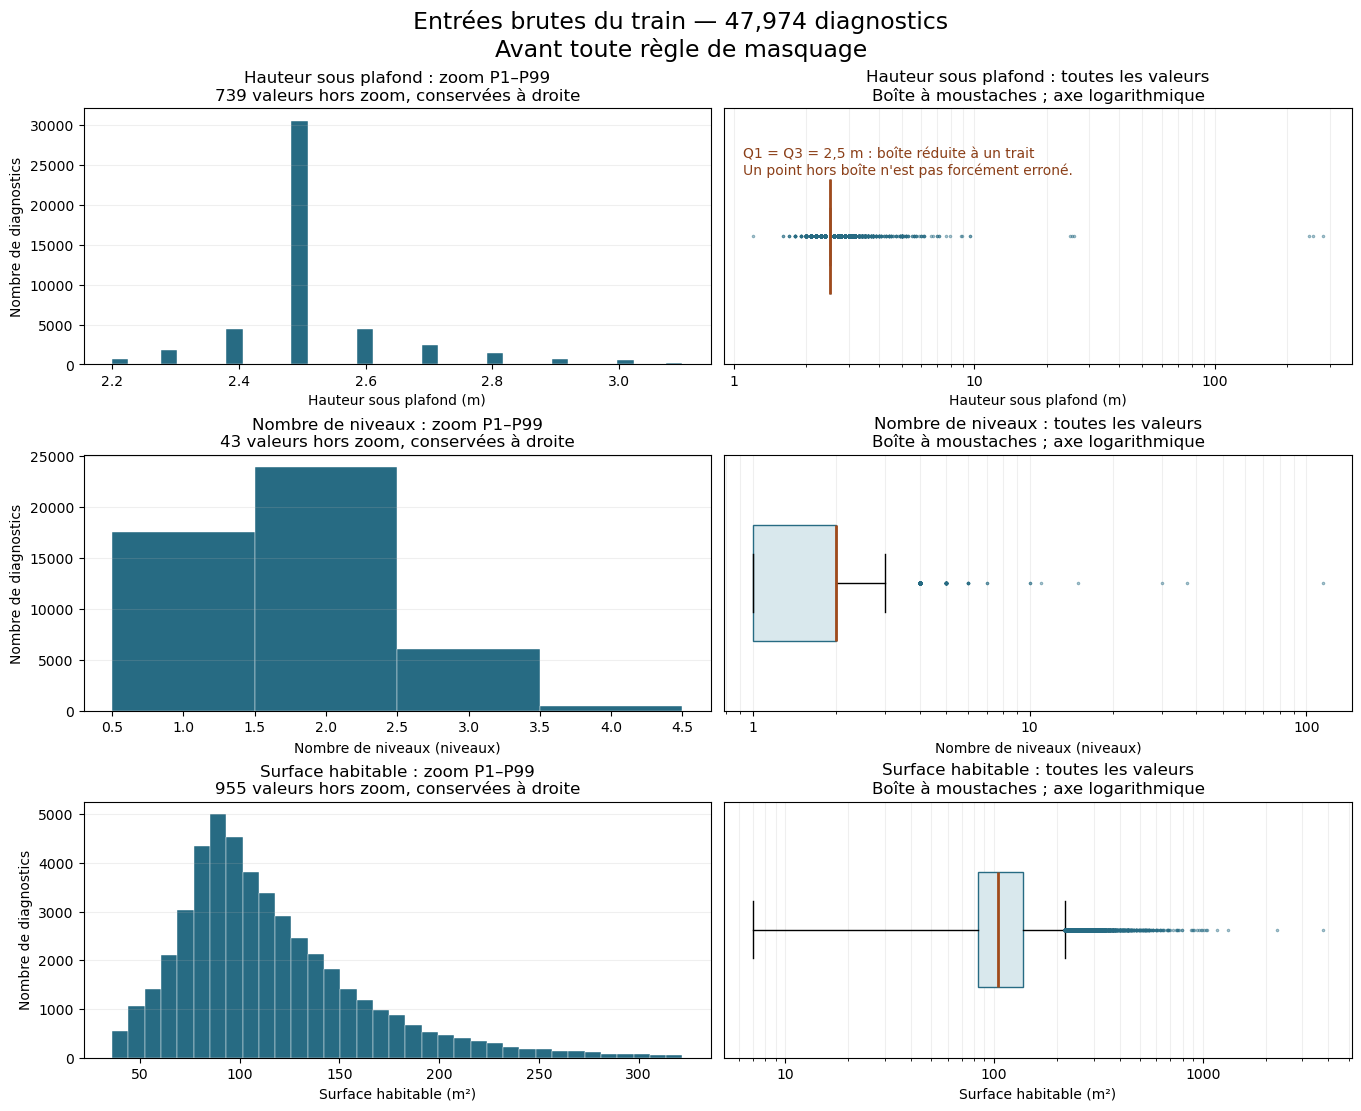

In [9]:
fig = outlier_audit.distribution_figure(df_train_raw)
plt.show()

À gauche : zoom P1–P99, avec le nombre de valeurs hors cadre.
À droite : toutes les valeurs sur un axe logarithmique.
La hauteur se concentre autour de 2,5 m ; les surfaces sont plus étalées.

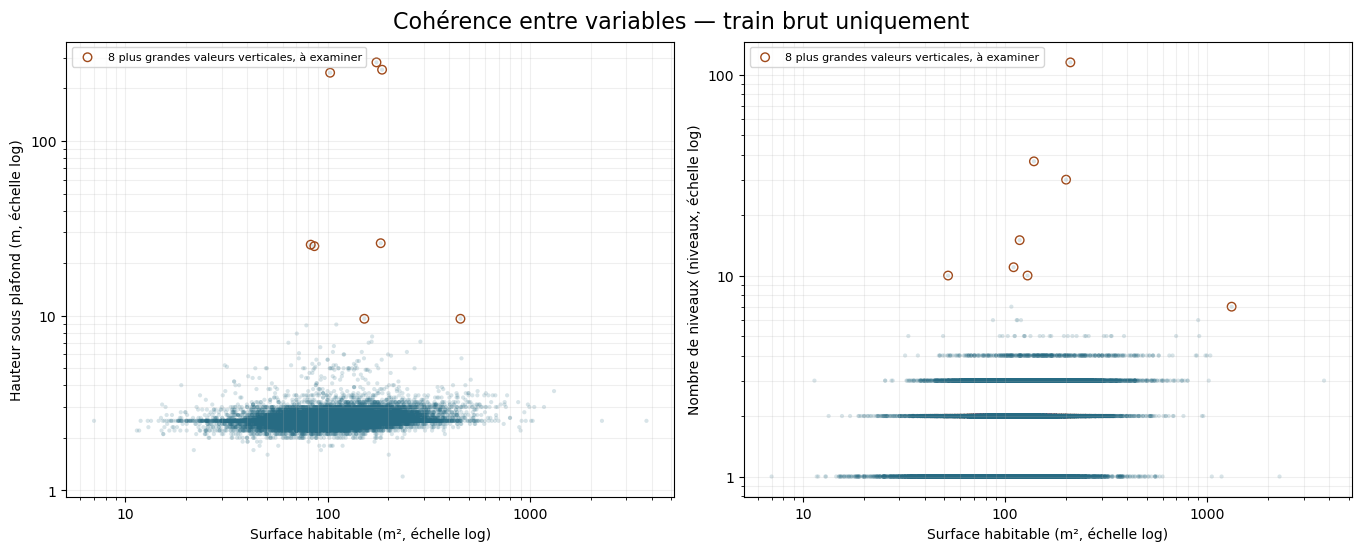

In [10]:
fig = outlier_audit.relationship_figure(df_train_raw)
plt.show()

Les cercles orange indiquent les huit plus grandes valeurs de l'axe vertical.
Des hauteurs de centaines de mètres ou des nombres de niveaux très élevés pour
une surface ordinaire suggèrent de vérifier les fiches et les unités.

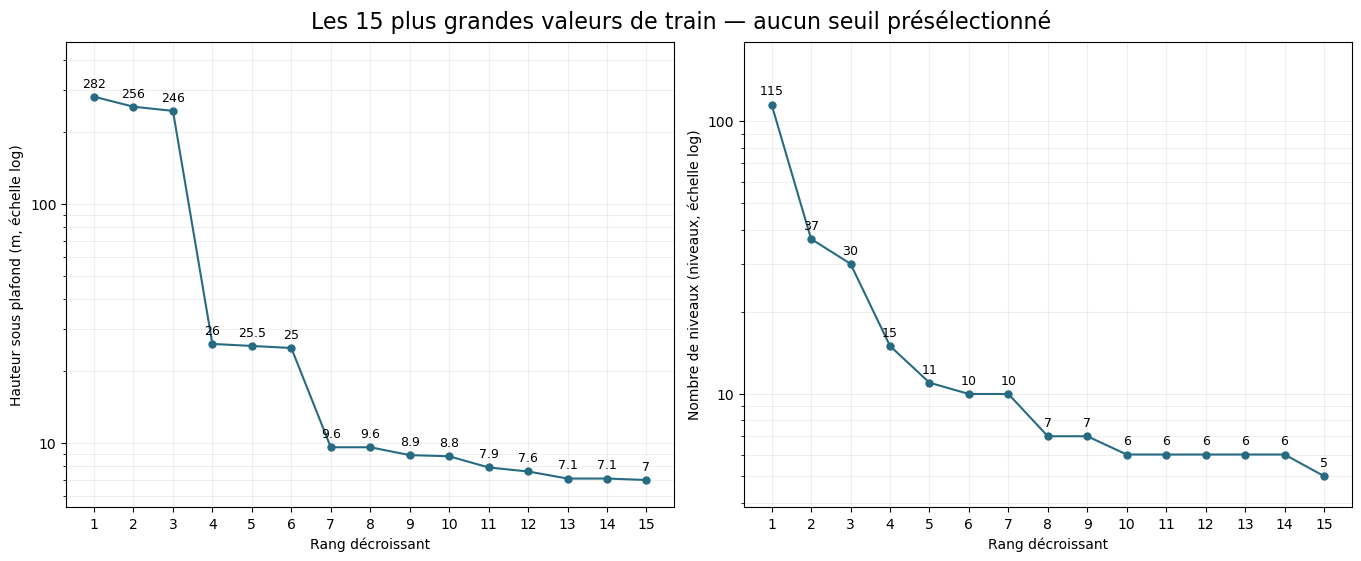

In [11]:
fig = outlier_audit.tail_figure(df_train_raw)
plt.show()

Hauteurs les plus élevées : 282, 256, 246, 26, 25,5 et 25 m, puis 9,6 m.
Une erreur d'unité ou de décimale est possible ; les petites hauteurs de 1,2–1,7 m
sont aussi à vérifier. Pour les niveaux, la proximité entre 10 et 11 ne suffit
pas à justifier une coupure à 10.

In [12]:
extreme_cases = outlier_audit.extreme_records(df_train_raw)
display(extreme_cases)

,field_examined,selection,numero_dpe,periode_construction,hauteur_sous_plafond,nombre_niveau_logement,surface_habitable_logement,version_dpe
0,hauteur_sous_plafond,largest_8,2501E1674693M,avant 1948,282.0,2.0,174.4,2.4
1,hauteur_sous_plafond,largest_8,2171E0805451Q,avant 1948,256.0,2.0,185.9,1.1
2,hauteur_sous_plafond,largest_8,2138E0566399B,2006-2012,246.0,1.0,102.9,1.0
3,hauteur_sous_plafond,largest_8,2501E2504206V,1948-1974,26.0,1.0,183.0,2.4
4,hauteur_sous_plafond,largest_8,2301E3942044F,2013-2021,25.5,2.0,82.5,2.3
5,hauteur_sous_plafond,largest_8,2642E0870902B,avant 1948,25.0,3.0,86.0,2.6
6,hauteur_sous_plafond,largest_8,2301E2322164D,avant 1948,9.6,1.0,151.9,2.2
7,hauteur_sous_plafond,largest_8,2369E0893027Y,avant 1948,9.6,1.0,453.6,2.2
8,hauteur_sous_plafond,smallest_5,2363E2599926R,avant 1948,1.2,3.0,235.0,2.3
9,hauteur_sous_plafond,smallest_5,2438E1436559W,1978-1982,1.6,1.0,50.5,2.3


Traitement : hauteurs > 10 m et niveaux > 20 remplacés par une valeur manquante
en section 5.1. Les autres valeurs sont conservées.
[Justification et fiches correspondantes](https://github.com/Yannisloum63/dpe-house-energy-prediction/blob/main/docs/outlier_review.md).

### 4.4 Distribution des cibles

La consommation par m² est la cible de régression ; la classe DPE A–G est celle
de classification. L'histogramme compte les diagnostics par intervalle de
25 kWh/m²/an, sur toute l'étendue des valeurs. Le diagramme en barres montre
les effectifs et proportions de chaque classe dans le train.

In [5]:
# Cibles du train, sans modification ni suppression de valeurs.
energy_train = df_train_raw[TARGET_REG]
labels_train = df_train_raw[TARGET_CLF]
assert len(energy_train) == 47974
assert energy_train.notna().all() and np.isfinite(energy_train).all()
assert labels_train.isin(list("ABCDEFG")).all()

energy_summary = pd.Series({
    "n": len(energy_train),
    "minimum": energy_train.min(),
    "Q1": energy_train.quantile(.25),
    "mediane": energy_train.median(),
    "moyenne": energy_train.mean(),
    "Q3": energy_train.quantile(.75),
    "P99": energy_train.quantile(.99),
    "maximum": energy_train.max(),
}).to_frame("kWh/m²/an (sauf n)")

dpe_counts = labels_train.value_counts().reindex(list("ABCDEFG"), fill_value=0)
dpe_summary = pd.DataFrame({
    "nombre": dpe_counts,
    "part_pct": 100 * dpe_counts / len(labels_train),
})
assert dpe_summary["nombre"].sum() == len(labels_train)
assert np.isclose(dpe_summary["part_pct"].sum(), 100)
display(energy_summary.round(1))
display(dpe_summary.round(2))


,kWh/m²/an (sauf n)
n,47974.0
minimum,22.2
Q1,153.0
mediane,215.3
moyenne,241.5
Q3,301.7
P99,673.1
maximum,2128.2


,nombre,part_pct
etiquette_dpe,,
A,1560,3.25
B,2468,5.14
C,10423,21.73
D,13745,28.65
E,9297,19.38
F,5379,11.21
G,5102,10.63


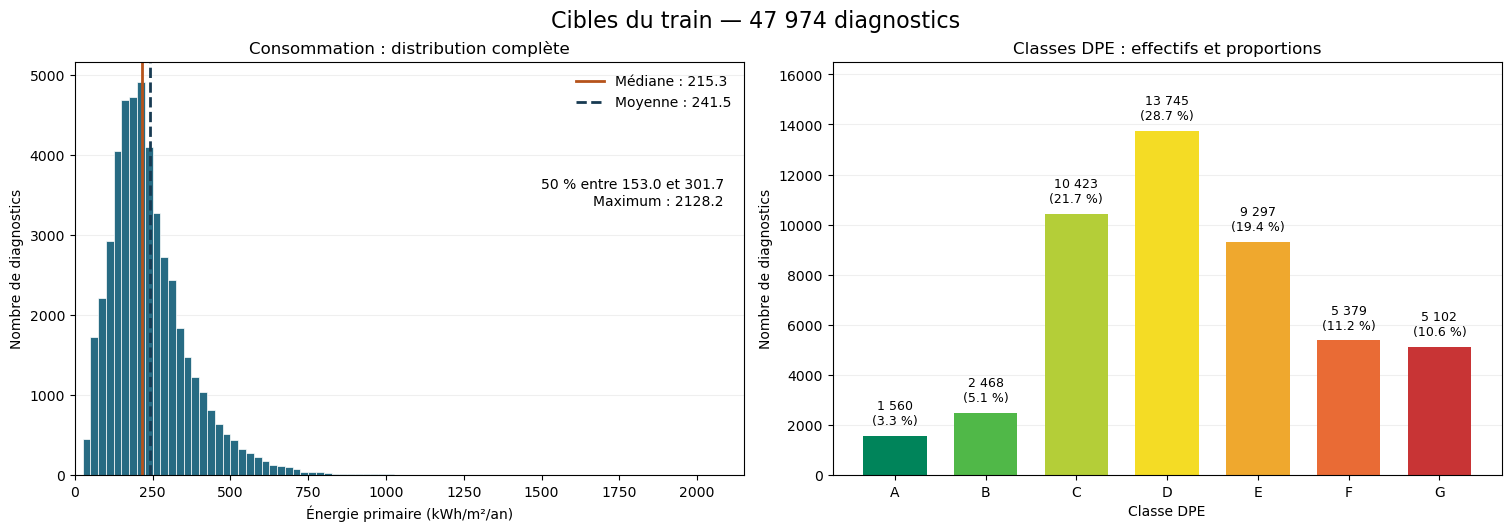

In [6]:
fig_targets, axes = plt.subplots(1, 2, figsize=(15, 5.2), layout="constrained")
fig_targets.suptitle("Cibles du train — 47 974 diagnostics", fontsize=16)

# Intervalles de 25 kWh/m²/an couvrant toutes les valeurs.
energy_bins = np.arange(0, energy_train.max() + 25, 25)
bin_counts, _, _ = axes[0].hist(
    energy_train, bins=energy_bins, color="#276b83",
    edgecolor="white", linewidth=.5,
)
assert int(bin_counts.sum()) == len(energy_train)
axes[0].axvline(energy_train.median(), color="#b6531b", linewidth=2,
               label=f"Médiane : {energy_train.median():.1f}")
axes[0].axvline(energy_train.mean(), color="#173a52", linestyle="--", linewidth=2,
               label=f"Moyenne : {energy_train.mean():.1f}")
axes[0].set(
    title="Consommation : distribution complète",
    xlabel="Énergie primaire (kWh/m²/an)",
    ylabel="Nombre de diagnostics",
    xlim=(0, energy_bins[-1]),
)
axes[0].legend(frameon=False, loc="upper right")
axes[0].text(.97, .72,
             f"50 % entre {energy_train.quantile(.25):.1f} et {energy_train.quantile(.75):.1f}\n"
             f"Maximum : {energy_train.max():.1f}",
             transform=axes[0].transAxes, ha="right", va="top", fontsize=10)
axes[0].grid(axis="y", alpha=.2)
axes[0].set_axisbelow(True)

class_colors = ["#00845a", "#50b848", "#b4ce38", "#f4dc25", "#efa82e", "#e96b35", "#c83435"]
bars = axes[1].bar(dpe_summary.index, dpe_summary["nombre"], color=class_colors, width=.7)
for bar, count, share in zip(bars, dpe_summary["nombre"], dpe_summary["part_pct"]):
    axes[1].text(bar.get_x() + bar.get_width()/2, count + dpe_counts.max()*.025,
                 f"{count:,}\n({share:.1f} %)".replace(",", " "),
                 ha="center", va="bottom", fontsize=9)
axes[1].set(
    title="Classes DPE : effectifs et proportions",
    xlabel="Classe DPE", ylabel="Nombre de diagnostics",
    ylim=(0, dpe_counts.max()*1.2),
)
axes[1].grid(axis="y", alpha=.2)
axes[1].set_axisbelow(True)
plt.show()


La consommation est asymétrique, avec une queue vers les grandes valeurs :
la moyenne (241,5) dépasse la médiane (215,3 kWh/m²/an). La moitié des diagnostics
se situe entre 153,0 et 301,7 ; le maximum atteint 2 128,2.
Ces valeurs élevées restent dans la cible : leur influence sur les erreurs de
régression sera à examiner lors de l'évaluation.

La classe D est la plus fréquente (28,65 %), contre 3,25 % pour A, soit environ
8,8 fois plus de diagnostics. Les sept classes sont présentes, mais inégalement
représentées. Pour la classification, comparer les résultats par classe et le
F1 macro en plus de l'accuracy, afin de ne pas masquer les difficultés sur A et B.

### 4.5 Relations entre les caractéristiques et les cibles

Comparaison de la consommation par m² et des classes A–G selon la période de
construction et la qualité de l'isolation. Les deux champs sont renseignés
pour les 47 974 diagnostics du train.

Dans les graphiques, la ligne orange indique la médiane et la boîte les 50 %
centraux. L'axe de consommation est logarithmique et les points extrêmes sont affichés.
Chaque barre DPE totalise 100 % de sa catégorie ; `n` indique son effectif.

In [5]:
# Données du train uniquement ; copie limitée aux champs étudiés.
eda_targets = df_train_raw[
    ["periode_construction", "qualite_isolation_enveloppe", TARGET_REG, TARGET_CLF]
].copy()
assert len(eda_targets) == 47974
assert eda_targets[TARGET_REG].notna().all() and eda_targets[TARGET_REG].gt(0).all()
assert eda_targets[TARGET_CLF].isin(list("ABCDEFG")).all()

category_orders = {
    "periode_construction": [
        "avant 1948", "1948-1974", "1975-1977", "1978-1982", "1983-1988",
        "1989-2000", "2001-2005", "2006-2012", "2013-2021", "après 2021",
    ],
    "qualite_isolation_enveloppe": ["insuffisante", "moyenne", "bonne", "très bonne"],
}
eda_summaries = {}
for field, order in category_orders.items():
    eda_targets[field] = eda_targets[field].fillna("Non renseigné")
    observed = set(eda_targets[field].unique())
    order += sorted(observed - set(order))
    category_orders[field] = [value for value in order if value in observed]
    summary = eda_targets.groupby(field).agg(
        n=(TARGET_REG, "size"),
        mediane=(TARGET_REG, "median"),
        Q1=(TARGET_REG, lambda x: x.quantile(.25)),
        Q3=(TARGET_REG, lambda x: x.quantile(.75)),
        part_AB_pct=(TARGET_CLF, lambda x: 100 * x.isin(["A", "B"]).mean()),
        part_FG_pct=(TARGET_CLF, lambda x: 100 * x.isin(["F", "G"]).mean()),
    ).reindex(category_orders[field])
    assert summary["n"].sum() == len(eda_targets)
    eda_summaries[field] = summary
    print(field)
    display(summary.round(1))


periode_construction


,n,mediane,Q1,Q3,part_AB_pct,part_FG_pct
periode_construction,,,,,,
avant 1948,17189,263.5,192.0,359.7,3.3,34.4
1948-1974,9889,269.2,196.9,359.5,3.5,37.7
1975-1977,1665,225.0,182.1,284.4,3.5,16.2
1978-1982,2876,223.8,180.4,271.8,3.4,10.8
1983-1988,2797,210.0,168.0,254.9,2.5,4.6
1989-2000,4392,184.2,148.3,225.9,4.7,2.3
2001-2005,2144,161.9,133.9,199.8,6.2,1.0
2006-2012,3420,147.6,119.0,181.0,13.5,0.5
2013-2021,2985,80.7,61.3,107.3,54.1,0.0


qualite_isolation_enveloppe


,n,mediane,Q1,Q3,part_AB_pct,part_FG_pct
qualite_isolation_enveloppe,,,,,,
insuffisante,19584,309.0,235.3,400.7,1.0,48.6
moyenne,7610,214.3,169.9,267.0,3.4,9.3
bonne,12397,176.5,134.4,221.4,9.9,1.8
très bonne,8383,133.7,87.5,178.4,27.9,0.4


#### Période de construction

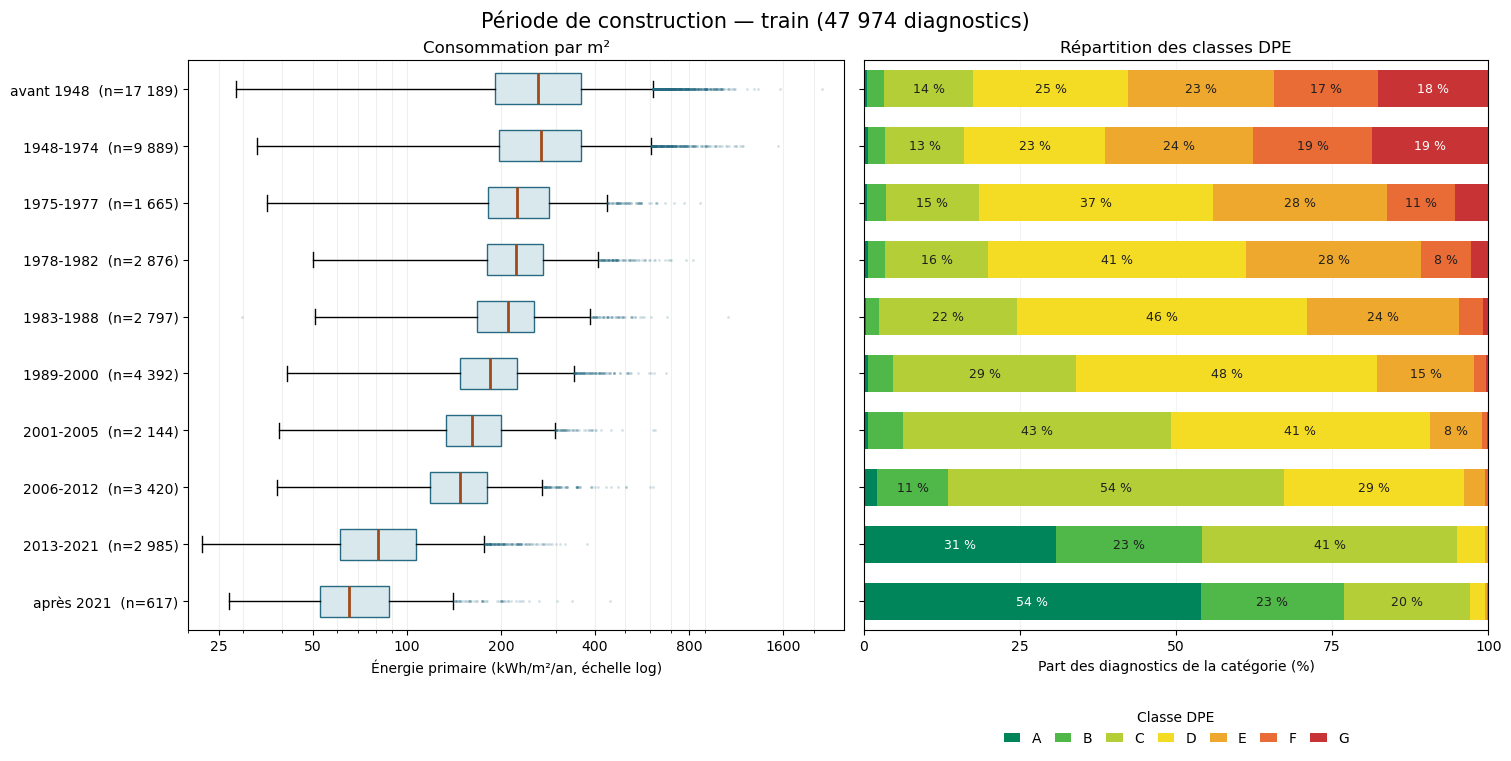

In [6]:
from matplotlib.ticker import ScalarFormatter

dpe_colors = ["#00845a", "#50b848", "#b4ce38", "#f4dc25", "#efa82e", "#e96b35", "#c83435"]

def plot_category_targets(field, title, height):
    order = category_orders[field]
    groups = [
        eda_targets.loc[eda_targets[field].eq(category), TARGET_REG].to_numpy()
        for category in order
    ]
    percentages = pd.crosstab(
        eda_targets[field], eda_targets[TARGET_CLF], normalize="index"
    ).reindex(index=order, columns=list("ABCDEFG"), fill_value=0) * 100
    assert np.allclose(percentages.sum(axis=1), 100)

    fig, axes = plt.subplots(
        1, 2, figsize=(15, height), sharey=True, layout="constrained",
        gridspec_kw={"width_ratios": [1.05, 1]},
    )
    positions = np.arange(len(order))
    axes[0].boxplot(
        groups, positions=positions, vert=False, widths=.55, patch_artist=True,
        boxprops={"facecolor": "#d9e8ed", "edgecolor": "#276b83"},
        medianprops={"color": "#a04a1b", "linewidth": 2},
        flierprops={"marker": ".", "markersize": 2, "alpha": .2,
                    "markeredgecolor": "#276b83"},
    )
    axes[0].set_xscale("log")
    axes[0].set_xticks([25, 50, 100, 200, 400, 800, 1600])
    axes[0].xaxis.set_major_formatter(ScalarFormatter())
    axes[0].set_xlim(20, 2500)
    axes[0].set_yticks(positions)
    axes[0].set_yticklabels([
        f"{category}  (n={len(values):,})".replace(",", " ")
        for category, values in zip(order, groups)
    ])
    axes[0].invert_yaxis()
    axes[0].set_title("Consommation par m²")
    axes[0].set_xlabel("Énergie primaire (kWh/m²/an, échelle log)")
    axes[0].grid(axis="x", alpha=.2, which="both")

    left = np.zeros(len(order))
    for label, color in zip("ABCDEFG", dpe_colors):
        values = percentages[label].to_numpy()
        axes[1].barh(positions, values, left=left, height=.65,
                     color=color, label=label)
        for y, width, start in zip(positions, values, left):
            if width >= 6:
                axes[1].text(start + width / 2, y, f"{width:.0f} %",
                             ha="center", va="center", fontsize=9,
                             color="white" if label in "AG" else "#202020")
        left += values
    axes[1].set_xlim(0, 100)
    axes[1].set_xticks([0, 25, 50, 75, 100])
    axes[1].set_title("Répartition des classes DPE")
    axes[1].set_xlabel("Part des diagnostics de la catégorie (%)")
    axes[1].legend(title="Classe DPE", ncol=7, loc="upper center",
                   bbox_to_anchor=(.5, -.12), frameon=False, handlelength=1.2,
                   columnspacing=1)
    axes[1].set_axisbelow(True)
    axes[1].grid(axis="x", alpha=.15)
    fig.suptitle(title + " — train (47 974 diagnostics)", fontsize=15)
    return fig

fig_period = plot_category_targets("periode_construction", "Période de construction", 7.5)
plt.show()


La consommation médiane passe de 269,2 kWh/m²/an pour 1948–1974 à 80,7 pour
2013–2021 et 65,5 après 2021. La part des classes A–B est respectivement de
3,5 %, 54,1 % et 76,8 %. La baisse n'est pas strictement régulière :
les logements d'avant 1948 ont une médiane légèrement inférieure à ceux de 1948–1974.
Les effectifs sont très différents (617 après 2021 contre 17 189 avant 1948).

#### Qualité de l'isolation de l'enveloppe

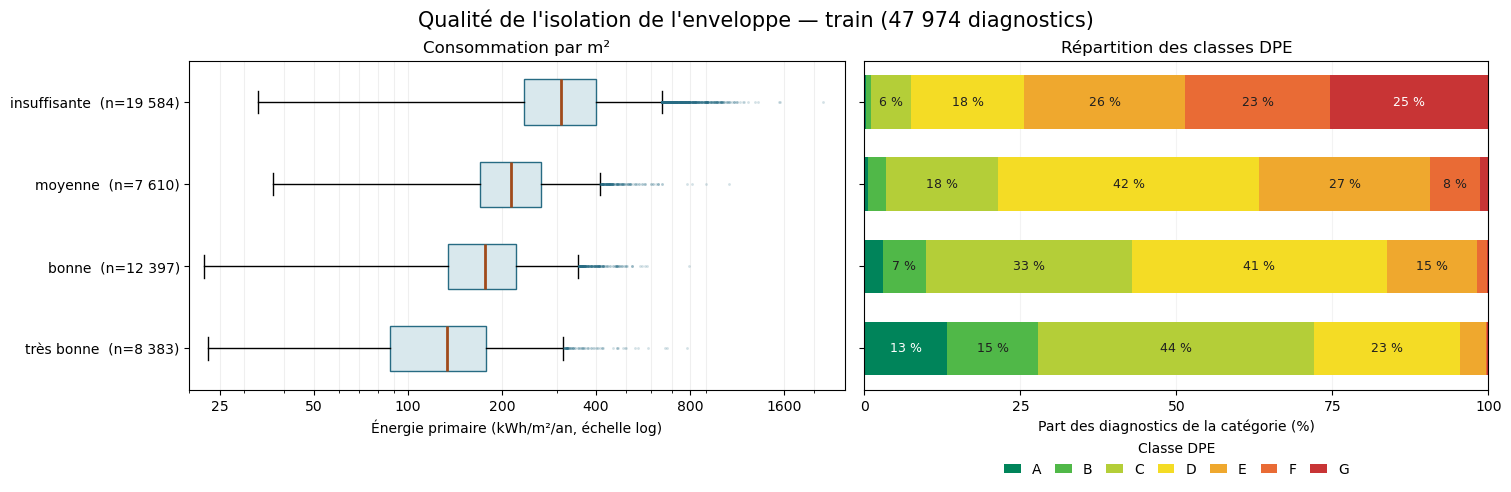

In [7]:
fig_insulation = plot_category_targets(
    "qualite_isolation_enveloppe", "Qualité de l'isolation de l'enveloppe", 4.8
)
plt.show()


La consommation médiane diminue de 309 à 133,7 kWh/m²/an entre une isolation
« insuffisante » et « très bonne ». La part des classes F–G passe de 48,6 % à 0,4 %.
Les distributions se recouvrent : la qualité d'isolation ne suffit pas à elle
seule à prédire la consommation.

### 4.6 Unsupervised clustering and correlation with the targets

### 4.7 Interprétation

- Les périodes récentes et les meilleures catégories d'isolation sont associées
  à une consommation par m² plus faible et à de meilleures classes DPE.
- Les distributions se recouvrent : ces deux variables ne déterminent pas seules
  la performance énergétique. Elles restent parmi les 17 entrées du modèle.
- Ces comparaisons ne séparent pas les effets de l'âge, des rénovations, du chauffage
  ou du climat. Elles décrivent des associations, pas un effet causal mesuré.
- La consommation étudiée est calculée par le DPE, pas relevée au compteur.
  L'étiquette DPE dépend notamment de cette consommation : les deux graphiques
  ne sont pas deux validations indépendantes.

## 5. Baseline & Ensemble Models

### 5.1 Données pour les modèles

Découpage fixe : **47 974 train, 16 007 validation et 16 019 test**.
Les diagnostics liés par RNB ou référence de remplacement restent ensemble.

Les cellules suivantes préparent `X_*` (17 entrées), `y_*_reg` (consommation)
et `y_*_clf` (classe A–G). Avec `apply_mask=True`, les hauteurs > 10 m et les
niveaux > 20 sont remplacés par une valeur manquante : 20 cellules au total, dont 9
dans le train. Aucune ligne n'est supprimée. Les graphiques de la section 4.3
montrent les valeurs brutes.

L'imputation, l'encodage et la standardisation restent à ajuster dans le Pipeline,
sur chaque pli d'entraînement. Utiliser `groups_train` pour la validation croisée.

[Options de chargement et limites du découpage](https://github.com/Yannisloum63/dpe-house-energy-prediction/blob/main/docs/data_preparation.md).

In [14]:
import hashlib
import importlib.util
from pathlib import Path

# Version du traitement et du découpage.
PREPARATION_VERSION = "8dde8ceb65a31e94500ff6f1965ff11794de3dc3"
PREPARATION_URL = (
    "https://raw.githubusercontent.com/"
    f"Yannisloum63/dpe-house-energy-prediction/{PREPARATION_VERSION}"
)
response = requests.get(PREPARATION_URL + "/scripts/prepare_data.py", timeout=60)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == "7913ebe910803f6bff6603f82a43fd51a0262c79f3bcae2309c91224df5ef4fc"
module_path = Path("prepare_data_shared.py")
module_path.write_bytes(response.content)
spec = importlib.util.spec_from_file_location("prepare_data_shared", module_path)
preparation = importlib.util.module_from_spec(spec)
spec.loader.exec_module(preparation)

In [15]:
df_raw, datasets, FEATURES, masked_values, preparation_report = preparation.load_shared_data(
    PREPARATION_URL, apply_mask=True
)

df_train = datasets["train"]
df_val = datasets["validation"]
df_test = datasets["test"]

display(pd.DataFrame({
    "ensemble": ["train", "validation", "test"],
    "lignes": [len(df_train), len(df_val), len(df_test)],
    "variables": [len(FEATURES)] * 3,
}))
display(masked_values.groupby("field").size().rename("valeurs_remplacees").to_frame())
print("Valeurs remplacées par NaN :", len(masked_values))
print("Groupes connus partagés :", preparation_report["cross_split_groups"])

assert len(masked_values) == preparation_report["masked_cells"] == 20
assert sum(len(frame) for frame in datasets.values()) == len(df_raw) == 80000
assert preparation_report["masking_applied"]
train_changes = masked_values[masked_values.numero_dpe.isin(df_train.numero_dpe)]
assert len(train_changes) == 9

# Vérifier que seules les cellules du journal ont changé dans le train.
expected_train = df_train_raw.set_index("numero_dpe")[FEATURES].copy()
for field, changes in train_changes.groupby("field"):
    expected_train.loc[changes.numero_dpe, field] = np.nan
pd.testing.assert_frame_equal(
    df_train.set_index("numero_dpe")[FEATURES].sort_index(),
    expected_train.sort_index(),
    check_dtype=False,
)

,ensemble,lignes,variables
0,train,47974,17
1,validation,16007,17
2,test,16019,17


,valeurs_remplacees
field,
hauteur_sous_plafond,13
nombre_niveau_logement,7


Valeurs remplacées par NaN : 20
Groupes connus partagés : 0


In [16]:
X_train = df_train[FEATURES].copy()
X_val = df_val[FEATURES].copy()
X_test = df_test[FEATURES].copy()

y_train_reg, y_val_reg, y_test_reg = (
    frame[TARGET_REG].copy() for frame in [df_train, df_val, df_test]
)
y_train_clf, y_val_clf, y_test_clf = (
    frame[TARGET_CLF].copy() for frame in [df_train, df_val, df_test]
)
groups_train = df_train["group_id"].copy()
NUMERIC_FEATURES = preparation_report["numeric_features"]
CATEGORICAL_FEATURES = preparation_report["categorical_features"]

print("Prêt pour les graphiques sur df_train et les modèles sur X_train / X_val.")

Prêt pour les graphiques sur df_train et les modèles sur X_train / X_val.


### 5.2 Preprocessing pipelines and models

### 5.3 Training and validation (nested cross-validation, learning curves)

### 5.4 Test and interpretation of results

## 6. Enhanced Models & Hyperparameter Tuning

### 6.1 Justification of choices

### 6.2 Tuning (parallel coordinates plot of the search)

### 6.3 Interpretation and analysis of the results

## 7. Conclusion and outlook